# 03 — Los hiperparámetros controlan la complejidad

Un **parámetro** se aprende de los datos (los coeficientes de una regresión). Un **hiperparámetro** se fija antes de
entrenar y determina la forma del espacio de hipótesis $\mathcal{H}$.

Para los árboles, `max_depth = d` define $\mathcal{H}_d$ = árboles de profundidad $\le d$, y
$\mathcal{H}_{d_1} \subseteq \mathcal{H}_{d_2}$ si $d_1 < d_2$: **más profundidad, más flexibilidad**.
Aquí se ve qué le pasa al error de entrenamiento y al de validación cuando sube la complejidad.

In [1]:
import sys
sys.path.append("../src")  # por si el paquete no está instalado con pip install -e .

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from proyecto_ml.data import SEMILLA, cargar_dataset, particionar
from proyecto_ml.metrics import resumen, rmse
from proyecto_ml.models import ARBOL, BOSQUE, KNN, LINEA_BASE, LINEAL, NOMBRES, construir_modelo

RESULTADOS = Path("..") / "resultados"
RESULTADOS.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 80)

from sklearn.model_selection import train_test_split
from proyecto_ml.tuning import curva_complejidad

In [2]:
datos = cargar_dataset()
X_dev, X_test, y_dev, y_test = particionar(datos)   # 80 % desarrollo, 20 % prueba (reservada)
print("desarrollo:", X_dev.shape, "| prueba:", X_test.shape)

# Dentro del conjunto de desarrollo se separa una validación (25 %) para ver las curvas.
X_tr, X_val, y_tr, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=SEMILLA)
print("entrenamiento:", X_tr.shape, "| validación:", X_val.shape)

desarrollo: (6972, 7) | prueba: (1744, 7)
entrenamiento: (5229, 7) | validación: (1743, 7)


## Curvas de complejidad

In [3]:
curva_arbol = curva_complejidad(ARBOL, "max_depth", list(range(1, 26)), X_tr, y_tr, X_val, y_val)
curva_knn = curva_complejidad(KNN, "n_neighbors", [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100], X_tr, y_tr, X_val, y_val)
curva_bosque = curva_complejidad(BOSQUE, "max_depth", [1, 2, 3, 5, 8, 12, 16, 20], X_tr, y_tr, X_val, y_val)

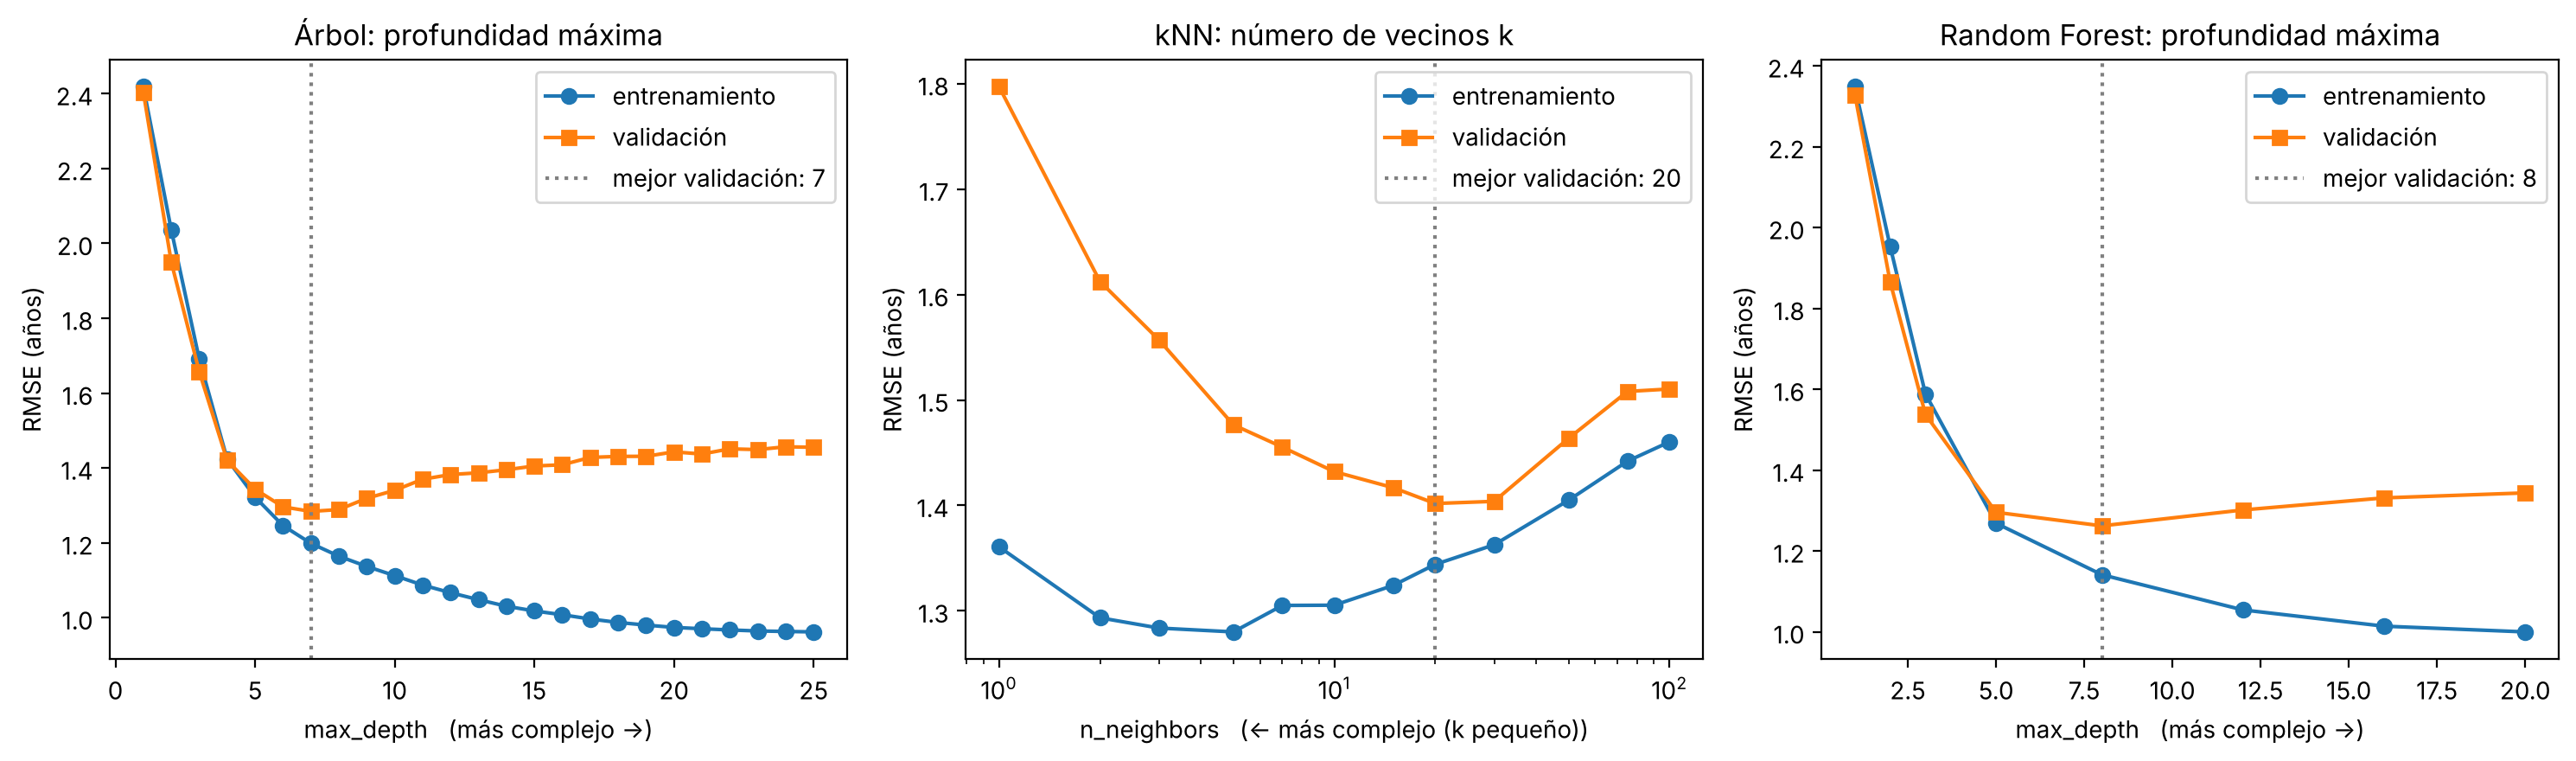

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
paneles = [
    (curva_arbol, "max_depth", "Árbol: profundidad máxima", "más complejo →"),
    (curva_knn, "n_neighbors", "kNN: número de vecinos k", "← más complejo (k pequeño)"),
    (curva_bosque, "max_depth", "Random Forest: profundidad máxima", "más complejo →"),
]
for ax, (curva, col, titulo, nota) in zip(axes, paneles):
    ax.plot(curva[col], curva["rmse_train"], "o-", label="entrenamiento")
    ax.plot(curva[col], curva["rmse_val"], "s-", label="validación")
    mejor = curva.loc[curva["rmse_val"].idxmin()]
    ax.axvline(mejor[col], color="gray", linestyle=":", label=f"mejor validación: {mejor[col]:g}")
    ax.set_xlabel(f"{col}   ({nota})")
    ax.set_ylabel("RMSE (años)")
    ax.set_title(titulo)
    ax.legend()
axes[1].set_xscale("log")
plt.tight_layout()
plt.savefig(RESULTADOS / "03_curvas_complejidad.png", dpi=150)
plt.show()

In [5]:
pd.DataFrame({
    "modelo": ["Árbol", "kNN", "Random Forest"],
    "hiperparámetro": ["max_depth", "n_neighbors", "max_depth"],
    "mejor valor (validación)": [
        curva_arbol.loc[curva_arbol["rmse_val"].idxmin(), "max_depth"],
        curva_knn.loc[curva_knn["rmse_val"].idxmin(), "n_neighbors"],
        curva_bosque.loc[curva_bosque["rmse_val"].idxmin(), "max_depth"],
    ],
    "RMSE validación": [curva_arbol["rmse_val"].min(), curva_knn["rmse_val"].min(), curva_bosque["rmse_val"].min()],
})

,modelo,hiperparámetro,mejor valor (validación),RMSE validación
0,Árbol,max_depth,7,1.284
1,kNN,n_neighbors,20,1.402
2,Random Forest,max_depth,8,1.262


### Lectura de resultados
- **Árbol:** el error de entrenamiento baja siempre al subir la profundidad (porque $\mathcal{H}_d \subseteq \mathcal{H}_{d+1}$), pero el de validación toca fondo en `max_depth = 7` (RMSE 1,284) y luego sube: ahí empieza el sobreajuste.
- **kNN:** `k = 20` minimiza la validación (1,402). Con $k$ pequeño el modelo es muy flexible (sobreajuste) y con $k$ grande es muy rígido (subajuste), por eso la complejidad va al revés que en el árbol.
- **Random Forest:** la mejor profundidad es 8 (1,262). Después la validación empeora poco (≈ 1,34 en profundidad 20, frente a ≈ 1,45 del árbol solo en profundidad 25), porque promediar muchos árboles reduce la varianza.

### Mi análisis
*(Escríbelo con tus palabras. Preguntas para guiarte: ¿qué le pasa al error de entrenamiento cuando aumenta la profundidad, y por qué siempre baja? ¿Qué le pasa al de validación? ¿En qué punto empieza el sobreajuste? ¿Por qué en kNN la complejidad es al revés (k pequeño = más complejo)? ¿Por qué el Random Forest sufre menos con la profundidad que un árbol solo?)*